In [2]:
import pandas as pd
import numpy as np
import seaborn as sb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

# Show all rows
pd.set_option('display.max_rows', None)

# Show all columns
pd.set_option('display.max_columns', None)

# (Optional) Show full text in cells
pd.set_option('display.max_colwidth', None)

# Load dataset
df = pd.read_excel('Dry_Bean_Dataset.xlsx')

# Preserve sample IDs separately
sample_ids = df['sample_id']

# Only use numerical measurement features
X = df.drop(columns=['sample_id', 'Class'])

# Inspect dataset
display("Dataset shape:", df.shape)
display("Missing values:", df.isna().sum().sum())
display("Duplicate rows:", df.duplicated().sum())
display("Duplicate measurements:", X.duplicated().sum())

# Standardize features
ss = StandardScaler()
# X_scaled = ss.fit_transform(X)

'Dataset shape:'

(13611, 18)

'Missing values:'

np.int64(13611)

'Duplicate rows:'

np.int64(0)

'Duplicate measurements:'

np.int64(68)

In [3]:
display("Missing values by column:")
display(df.isna().sum())

display("Columns with missing values:")
display(df.columns[df.isna().any()].tolist())

display("Duplicate measurement examples:")
display(X[X.duplicated(keep=False)].head(10))

'Missing values by column:'

sample_id              0
Area                   0
Perimeter              0
MajorAxisLength        0
MinorAxisLength        0
AspectRation           0
Eccentricity           0
ConvexArea             0
EquivDiameter          0
Extent                 0
Solidity               0
roundness              0
Compactness            0
ShapeFactor1           0
ShapeFactor2           0
ShapeFactor3           0
ShapeFactor4           0
Class              13611
dtype: int64

'Columns with missing values:'

['Class']

'Duplicate measurement examples:'

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
145,54187,919.972,372.954622,186.450123,2.000292,0.866067,54828,262.665246,0.759241,0.988309,0.804555,0.704282,0.006883,0.001045,0.496013,0.992171
196,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847
226,60134,984.152,385.504338,199.989509,1.927623,0.854912,61079,276.703789,0.681745,0.984528,0.780199,0.717771,0.006411,0.001050,0.515195,0.993102
265,60516,970.091,391.907258,199.308475,1.966335,0.861026,61355,277.581275,0.760758,0.986325,0.808081,0.708283,0.006476,0.001005,0.501665,0.986441
289,46777,845.203,349.187769,171.167126,2.040040,0.871618,47247,244.045746,0.821413,0.990052,0.822849,0.698895,0.007465,0.001099,0.488455,0.996467
378,60716,984.188,404.263088,192.452037,2.100591,0.879415,61532,278.039587,0.819291,0.986739,0.787693,0.687769,0.006658,0.000919,0.473026,0.993635
384,52313,896.732,352.482089,189.300951,1.862020,0.843550,53085,258.083282,0.785198,0.985457,0.817512,0.732188,0.006738,0.001195,0.536100,0.998228
532,57029,953.664,388.137971,187.927020,2.065365,0.874971,57971,269.465356,0.784065,0.983750,0.787979,0.694251,0.006806,0.000975,0.481985,0.995475
633,38891,791.343,319.499996,156.869619,2.036723,0.871168,39651,222.525412,0.650025,0.980833,0.780422,0.696480,0.008215,0.001192,0.485085,0.987983
653,59664,982.497,410.284948,185.624314,2.210297,0.891801,60327,275.620326,0.623898,0.989010,0.776712,0.671778,0.006877,0.000864,0.451285,0.997475


In [4]:
X = df.drop(columns=['sample_id', 'Class'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
X.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


---------KMeans---------

KMeans with normalization

In [6]:
# Kmeans Train the dataset on the data an output the groups

x_kmeans = ss.fit_transform(X)
SS_total = np.sum(((x_kmeans - x_kmeans.mean(axis=0)) ** 2))
km = KMeans(n_clusters=7, random_state=41, n_init=10)
labels = km.fit_predict(x_kmeans)

df_k = pd.DataFrame(
    data=[
        df.iloc[:,0],
        labels
    ],
    index=["Sample_id","Group"],
).transpose()


In [7]:
df_k['Group'].value_counts() # num in each group

# explained_variance
SS_in = km.inertia_

Metrics, visualization and traits

In [8]:
df_k # model results
silhouette_score(x_kmeans, df_k['Group']) # .259
explained_variance = 1 - SS_in / SS_total # 73.028%

<Axes: xlabel='PC1', ylabel='PC2'>

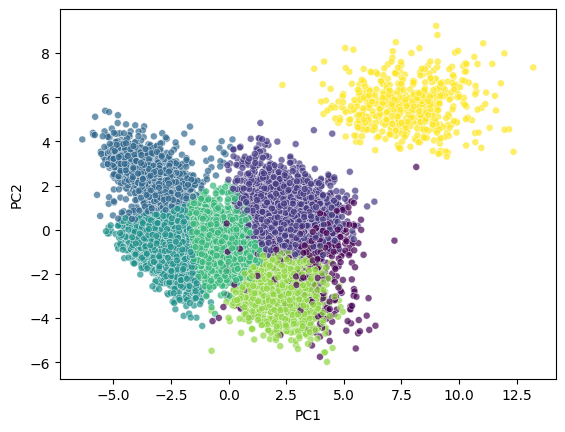

In [9]:
pca_2d = PCA(n_components=2)

x_kmeans_2d = pca_2d.fit_transform(x_kmeans)

# Create visualization dataframe
df_kmeans_viz = pd.DataFrame({
    'PC1': x_kmeans_2d[:, 0],
    'PC2': x_kmeans_2d[:, 1],
    'Group': labels
})

# Plot

sb.scatterplot(
    data=df_kmeans_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='viridis',
    s=25,
    alpha=0.7,
    legend=False
)

In [10]:
df_cluster_analysis = df.copy()
df_cluster_analysis['Cluster'] = df_k['Group']
df_cluster_analysis.head()
df_cluster_analysis.groupby('Cluster')[df_cluster_analysis.columns].mean()

,sample_id,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,Cluster
Cluster,,,,,,,,,,,,,,,,,,,
0,6931.593346,65249.218115,1004.004044,385.946044,216.962435,1.785230,0.823276,67014.561922,286.432691,0.730076,0.973333,0.803850,0.743535,0.006071,0.001151,0.553931,0.981414,NaN,0.0
1,6840.912097,74020.445565,1060.521567,394.219331,240.076083,1.646073,0.787793,75137.553629,306.389737,0.757135,0.985066,0.825338,0.779112,0.005362,0.001226,0.608187,0.993742,NaN,1.0
2,6811.227250,39397.049680,721.920716,248.672729,201.351631,1.235780,0.579352,39780.226758,223.500572,0.773063,0.990365,0.946920,0.899735,0.006360,0.002578,0.810088,0.998332,NaN,2.0
3,6891.289199,31541.082673,658.121514,243.255796,164.897580,1.477919,0.732717,31910.480203,199.911538,0.756104,0.988329,0.911019,0.822289,0.007791,0.002199,0.676666,0.997042,NaN,3.0
4,6647.785599,44435.414979,794.083113,298.233263,190.053063,1.571649,0.768416,44973.004500,237.472358,0.747639,0.988026,0.883397,0.796891,0.006756,0.001683,0.635534,0.995721,NaN,4.0
5,6844.180893,53676.967213,919.899584,373.681727,183.381913,2.040283,0.870002,54381.845110,260.819332,0.702961,0.986961,0.794549,0.698762,0.007024,0.001036,0.488699,0.993583,NaN,5.0
6,6787.250000,173667.573077,1586.450225,593.525661,374.527144,1.585856,0.770630,175992.065385,469.206095,0.776630,0.986943,0.864496,0.792556,0.003440,0.000844,0.629088,0.991874,NaN,6.0


Kmeans with pca

In [11]:
pca_full = PCA()
X_pca = pca_full.fit_transform(X_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

for i, variance in enumerate(cumulative_variance, start=1):
    print(f"{i} components: {variance:.4f}")

    # K-Means using PCA features

# Keep the first 8 principal components
x_kmeans_pca = X_pca[:, :8]

# Train K-Means
km2 = KMeans(n_clusters=7, random_state=41, n_init=10)
labels_2 = km2.fit_predict(x_kmeans_pca)

# Store sample IDs and cluster assignments
df_k_means_pca = pd.DataFrame({
    "Sample_id": sample_ids,
    "Group": labels_2
})

# Metrics
print("Variance retained:", 
      f"{pca_full.explained_variance_ratio_[:8].sum():.2%}")

print("Silhouette score:", 
      silhouette_score(x_kmeans_pca, labels_2))

print("\nCluster sizes:")
print(df_k_means_pca["Group"].value_counts().sort_index())

1 components: 0.5547
2 components: 0.8190
3 components: 0.8990
4 components: 0.9502
5 components: 0.9776
6 components: 0.9891
7 components: 0.9960
8 components: 0.9993
9 components: 0.9998
10 components: 0.9999
11 components: 1.0000
12 components: 1.0000
13 components: 1.0000
14 components: 1.0000
15 components: 1.0000
16 components: 1.0000
Variance retained: 99.93%
Silhouette score: 0.30976197569812064

Cluster sizes:
Group
0    2478
1    3111
2    2033
3    3157
4     520
5     541
6    1771
Name: count, dtype: int64


Metrics, visualization, and traits

In [12]:
# explained_variance = 1 - SS_in2 / SS_total # 73.325%

silhouette_score(x_kmeans_pca, df_k_means_pca['Group']) # .2595

df_k_means_pca['Group'].value_counts() #Num Values in each group

Group
3    3157
1    3111
0    2478
2    2033
6    1771
5     541
4     520
Name: count, dtype: int64

<Axes: xlabel='PC1', ylabel='PC2'>

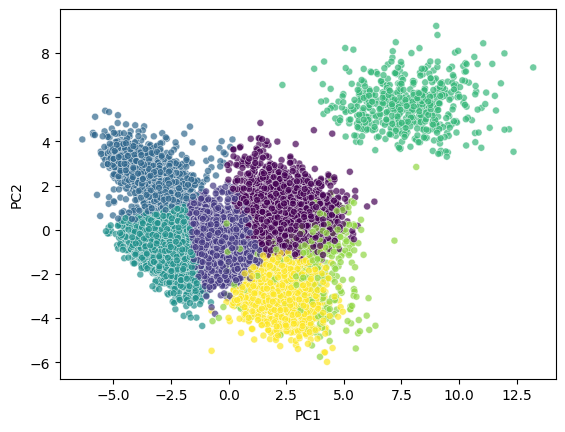

In [13]:
# Use the existing 2D PCA coordinates, but color by PCA K-Means labels
df_kmeans_viz_2 = pd.DataFrame({
    'PC1': x_kmeans_2d[:, 0],
    'PC2': x_kmeans_2d[:, 1],
    'Group': labels_2
})

sb.scatterplot(
    data=df_kmeans_viz_2,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='viridis',
    s=25,
    alpha=0.7,
    legend=False
)

In [14]:
df_cluster_analysis_2 = X.copy()
df_cluster_analysis_2['Cluster'] = labels_2

df_cluster_analysis_2.groupby('Cluster').mean()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Cluster,,,,,,,,,,,,,,,,
0,74026.894270,1060.511425,394.221738,240.095511,1.645940,0.787755,75144.114609,306.403129,0.757171,0.985066,0.825415,0.779143,0.005361,0.001226,0.608235,0.993742
1,44435.414979,794.083113,298.233263,190.053063,1.571649,0.768416,44973.004500,237.472358,0.747639,0.988026,0.883397,0.796891,0.006756,0.001683,0.635534,0.995721
2,39397.049680,721.920716,248.672729,201.351631,1.235780,0.579352,39780.226758,223.500572,0.773063,0.990365,0.946920,0.899735,0.006360,0.002578,0.810088,0.998332
3,31541.082673,658.121514,243.255796,164.897580,1.477919,0.732717,31910.480203,199.911538,0.756104,0.988329,0.911019,0.822289,0.007791,0.002199,0.676666,0.997042
4,173667.573077,1586.450225,593.525661,374.527144,1.585856,0.770630,175992.065385,469.206095,0.776630,0.986943,0.864496,0.792556,0.003440,0.000844,0.629088,0.991874
5,65249.218115,1004.004044,385.946044,216.962435,1.785230,0.823276,67014.561922,286.432691,0.730076,0.973333,0.803850,0.743535,0.006071,0.001151,0.553931,0.981414
6,53690.918125,920.072580,373.701552,183.418753,2.040024,0.869961,54396.104461,260.852058,0.702971,0.986960,0.794475,0.698810,0.007023,0.001036,0.488767,0.993583


Model selection and assesment

In [23]:
# Compare clustering configurations

configurations = {
    "K-Means - Standardized": (X_scaled, labels),
    "K-Means - PCA": (x_kmeans_pca, labels_2),
}

comparison = []

for name, (features, cluster_labels) in configurations.items():
    sizes = pd.Series(cluster_labels).value_counts().sort_index()

    comparison.append({
        "Configuration": name,
        "Silhouette Score": round(
            silhouette_score(features, cluster_labels), 4
        ),
        "Number of Clusters": len(sizes),
        "Cluster Sizes": sizes.to_dict()
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,Configuration,Silhouette Score,Number of Clusters,Cluster Sizes
0,K-Means - Standardized,0.3094,7,"{0: 541, 1: 2480, 2: 2033, 3: 3157, 4: 3111, 5: 1769, 6: 520}"
1,K-Means - PCA,0.3098,7,"{0: 2478, 1: 3111, 2: 2033, 3: 3157, 4: 520, 5: 541, 6: 1771}"


In [16]:
print(
    "K-Means agreement:",
    round(adjusted_rand_score(labels, labels_2), 4)
)

K-Means agreement: 0.9997


In [21]:
filename = 'results.csv'

output = pd.DataFrame({
    "sample_id": sample_ids,
    "Class_id": labels_2
})

output.to_csv(filename, index=False)

print(f"\nExported {filename}")
print("Rows:", len(output))
print("Unique clusters:", output["Class_id"].nunique())


Exported results.csv
Rows: 13611
Unique clusters: 7
